# Collateral Haircut Model
### A Credit Exposure Management (CEM) project — how much is a client's collateral *really* worth to the bank?

---

**The business problem.** A client borrows from the bank (margin lending, repo, prime brokerage) and posts **shares as collateral**. If the client defaults, the bank must **sell** those shares to recover its money. The sale value can be far below today's price because:

| Risk | What goes wrong | Model component |
|---|---|---|
| **Market risk** | Price falls during the close-out period | Volatility-based haircut |
| **Liquidity risk** | Position too big to sell quickly → longer exposure + price impact | Liquidity add-on |
| **Concentration risk** | One stock dominates the collateral pool | Concentration add-on |
| **Wrong-way risk** | Collateral falls *because of* the same thing that makes the client default | WWR multiplier / ineligibility |

$$\text{Lending value} = \text{Market value} \times (1 - \text{Haircut}), \qquad \text{Haircut} = \min\big(100\%,\; (H_{mkt} + H_{liq} + H_{conc}) \times M_{WWR}\big)$$

> **Archegos (2021)** is the textbook case: huge, concentrated, illiquid single-stock positions financed with too-small haircuts. When prices fell, banks that sold slowly lost billions. Nomura's loss was among the largest. Every component in this notebook exists to prevent that.

**What this notebook builds**

| # | Section |
|---|---|
| 1 | Setup & data (prices **and** volumes) |
| 2 | Liquidity & volatility risk map |
| 3 | **Market-risk haircut** — historical, parametric, stressed |
| 4 | **Liquidity add-on** — days-to-liquidate & square-root price impact |
| 5 | **Concentration add-on** |
| 6 | **Wrong-way risk** |
| 7 | The full haircut engine on three client pools + waterfall |
| 8 | Stress test — does the collateral cover the loan? Model vs flat haircut |
| 9 | Out-of-sample backtest of haircuts |
| 10 | Published haircut grid (stock × position size) |
| 11 | Summary & interview talking points |

## 1. Setup
```bash
pip install numpy pandas matplotlib scipy yfinance
```

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.patches import Patch
from scipy import stats
import warnings

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
pd.set_option("display.width", 140)

In [ ]:
# ---------- Plot styling: one consistent, clean look for every chart ----------
PALETTE = {
    "navy":  "#1f3b73",   # primary series
    "coral": "#e4572e",   # risk / losses / warnings
    "teal":  "#17a398",   # hedges / gains / safe
    "gold":  "#f2a541",   # highlights
    "plum":  "#8e5572",
    "slate": "#5c6b7a",
    "sky":   "#4f9dde",
    "olive": "#7a9e3f",
}
CYCLE = ["#1f3b73", "#e4572e", "#17a398", "#f2a541", "#8e5572",
         "#4f9dde", "#7a9e3f", "#5c6b7a", "#c44569", "#2d6a4f", "#b07d2b", "#6a4c93"]

plt.rcParams.update({
    "figure.figsize": (12, 5.5),
    "figure.dpi": 110,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#9aa5b1",
    "axes.grid": True,
    "grid.color": "#d9dee4",
    "grid.linestyle": "--",
    "grid.alpha": 0.7,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.titlepad": 24,
    "axes.labelsize": 11,
    "axes.labelcolor": "#2b3440",
    "xtick.color": "#4a5561",
    "ytick.color": "#4a5561",
    "legend.frameon": False,
    "legend.fontsize": 10,
    "font.family": "DejaVu Sans",
    "axes.prop_cycle": plt.cycler(color=CYCLE),
    "axes.axisbelow": True,          # gridlines behind bars
})

CRORE, LAKH = 1e7, 1e5

def fmt_inr(x, pos=None):
    """Axis/text formatter: rupees -> Cr / L (Indian units)."""
    sign, ax_ = ("−" if x < 0 else ""), abs(x)
    if ax_ >= CRORE:
        return f"{sign}₹{ax_ / CRORE:,.1f} Cr"
    if ax_ >= LAKH:
        return f"{sign}₹{ax_ / LAKH:,.1f} L"
    return f"{sign}₹{ax_:,.0f}"

inr_axis = mtick.FuncFormatter(fmt_inr)
pct_axis = mtick.PercentFormatter(1.0, decimals=0)

def subtitle(ax, text):
    """Small grey explanatory line under a chart title."""
    ax.text(0, 1.01, text, transform=ax.transAxes, fontsize=9.5, color="#6b7785", va="bottom")

### 1.1 Model parameters
These are the **policy choices** a CEM team debates and gets approved by risk committees. Change them and watch every result move.

In [ ]:
CONFIDENCE      = 0.99    # haircut covers 99% of close-out price moves
MPOR            = 10      # days to close out a defaulted client (base case)
HAIRCUT_FLOOR   = 0.05    # no equity ever gets less than a 5% haircut
ADV_WINDOW      = 60      # days used for Average Daily traded Value
PARTICIPATION   = 0.10    # bank sells at most 10% of daily volume to avoid crashing the price
IMPACT_Y        = 1.0     # square-root price-impact coefficient (literature: ~0.5–1.5)
CONC_THRESHOLD  = 0.20    # single stock > 20% of the pool triggers an add-on
CONC_SLOPE      = 0.50    # +0.5% haircut for every 1% above the threshold
WWR_RHO         = 0.50    # correlation with the client above which WWR applies
WWR_K           = 1.00    # multiplier slope: haircut × (1 + K·(ρ − 0.5))
START           = "2019-01-01"
z = stats.norm.ppf(CONFIDENCE)

### 1.2 Data — prices and **traded volumes**
Liquidity needs volume data, which Yahoo Finance provides for NSE stocks. If you are offline, the notebook falls back to a realistic simulator.

In [ ]:
UNIVERSE = {
    #  ticker          sector        sim_start  sim_vol  sim_beta  sim_ADV(₹Cr)
    "RELIANCE.NS":   ("Energy",       1300,      0.25,    1.00,     1200),
    "HDFCBANK.NS":   ("Banks",        1100,      0.22,    0.95,     1800),
    "ICICIBANK.NS":  ("Banks",         360,      0.26,    1.10,     1400),
    "SBIN.NS":       ("Banks",         300,      0.31,    1.20,     1100),
    "TCS.NS":        ("IT",           1900,      0.22,    0.70,      900),
    "INFY.NS":       ("IT",            650,      0.25,    0.75,     1000),
    "ITC.NS":        ("FMCG",          280,      0.21,    0.60,      600),
    "HINDUNILVR.NS": ("FMCG",         1750,      0.20,    0.55,      450),
    "BHARTIARTL.NS": ("Telecom",       320,      0.25,    0.80,      900),
    "LT.NS":         ("Industrials",  1300,      0.27,    1.10,      700),
    "ASIANPAINT.NS": ("Consumer",     1350,      0.24,    0.75,      350),
    "ADANIENT.NS":   ("Conglomerate",  170,      0.50,    1.30,      500),
}
TICKERS = list(UNIVERSE)
INDEX = "^NSEI"          # Nifty 50 index
SECTOR = {t: v[0] for t, v in UNIVERSE.items()}
SHORT = {t: t.replace(".NS", "") for t in TICKERS}

In [ ]:
def simulate_market_data(universe, start="2019-01-01", end="2026-09-30", seed=7):
    """
    Offline fallback: realistic synthetic prices & volumes for the universe.

    Model (daily log-returns):
        r_i = beta_i * market + sector_s + idio_i
      * market factor has Student-t(4) shocks (fat tails) and a volatility regime
        that triples during a Covid-style crash (Feb-May 2020), then decays,
      * a sector factor makes banks move with banks, IT with IT, etc.,
      * idiosyncratic noise is scaled so each stock hits its target annual vol.
    Volumes are lognormal around each stock's average daily traded value and spike in stress.
    """
    rng = np.random.default_rng(seed)
    dates = pd.bdate_range(start, end)
    n = len(dates)

    # --- volatility regime (1 = normal, 3 = crisis) ---
    regime = np.ones(n)
    c0 = dates.searchsorted(pd.Timestamp("2020-02-24"))
    c1 = dates.searchsorted(pd.Timestamp("2020-05-15"))
    regime[c0:c1] = 3.0
    tail = np.arange(n - c1)
    regime[c1:] = 1 + 1.2 * np.exp(-tail / 60)          # slow calm-down after the crash
    r0 = dates.searchsorted(pd.Timestamp("2022-02-20"))   # a smaller 2022-style wobble
    regime[r0:r0 + 70] *= 1.5

    t_scale = np.sqrt(4 / 2)                              # var of t(4) = 2 -> rescale to unit var
    mkt_vol = 0.15 / np.sqrt(252)
    market = mkt_vol * regime * rng.standard_t(4, n) / t_scale
    market += 0.13 / 252                                  # equity drift
    market[c0:c0 + 22] -= 0.017                           # the crash itself (~ -30%)
    market[c1:c1 + 160] += 0.0018                         # recovery

    sectors = sorted({v[0] for v in universe.values()})
    sec_vol = 0.09 / np.sqrt(252)
    sec_f = {s: sec_vol * regime * rng.standard_t(4, n) / t_scale for s in sectors}

    prices, volumes = {}, {}
    for tkr, (sec, p0, vol, beta, adv_cr) in universe.items():
        d_vol = vol / np.sqrt(252)
        idio_vol = np.sqrt(max(d_vol**2 - (beta * mkt_vol)**2 - sec_vol**2, (0.3 * d_vol)**2))
        idio = idio_vol * np.sqrt(regime) * rng.standard_t(4, n) / t_scale
        r = beta * market + sec_f[sec] + idio
        if tkr.startswith("ADANI"):                       # one idiosyncratic blow-up (short-seller style)
            j = dates.searchsorted(pd.Timestamp("2023-01-25"))
            r[j:j + 8] -= 0.07
        px = p0 * np.exp(np.cumsum(r))
        prices[tkr] = px
        traded_value = adv_cr * 1e7 * np.exp(rng.normal(0, 0.35, n)) * regime**0.6
        volumes[tkr] = traded_value / px

    prices["^NSEI"] = 10800 * np.exp(np.cumsum(market))
    volumes["^NSEI"] = np.full(n, np.nan)
    return (pd.DataFrame(prices, index=dates).rename_axis("Date"),
            pd.DataFrame(volumes, index=dates).rename_axis("Date"))


def load_market_data(universe, index="^NSEI", start="2019-01-01"):
    """Try Yahoo Finance first (real NSE data); fall back to simulation if offline."""
    tickers = list(universe) + [index]
    try:
        import logging
        import yfinance as yf
        logging.getLogger("yfinance").setLevel(logging.CRITICAL)   # silence per-ticker noise
        raw = yf.download(tickers, start=start, auto_adjust=True, progress=False, threads=True)
        close = raw["Close"].reindex(columns=tickers)
        volume = raw["Volume"].reindex(columns=tickers)
        close = close.dropna(how="all").ffill().dropna()
        volume = volume.reindex(close.index)
        if len(close) < 500 or close.isna().any().any():
            raise ValueError(f"incomplete download ({close.shape})")
        return close, volume, "Yahoo Finance (live NSE data)"
    except Exception as e:
        print(f"⚠ Live download unavailable ({type(e).__name__}: {str(e)[:80]}).")
        print("  → Using simulated market data so the notebook still runs end-to-end.")
        close, volume = simulate_market_data(universe, start=start)
        return close, volume, "Simulated (offline fallback)"

In [ ]:
prices_all, volumes_all, DATA_SOURCE = load_market_data(UNIVERSE, INDEX, START)
prices  = prices_all[TICKERS]
volumes = volumes_all[TICKERS]
log_ret = np.log(prices).diff().dropna()

# Average Daily traded Value in ₹ (median is robust to block-trade spikes)
traded_value = prices * volumes
adv = traded_value.rolling(ADV_WINDOW).median().iloc[-1]
sig_d = log_ret.iloc[-250:].std()                       # current daily volatility

print(f"Data source : {DATA_SOURCE}")
print(f"Date range  : {prices.index[0]:%d %b %Y} → {prices.index[-1]:%d %b %Y}  ({len(prices):,} days)")
overview = pd.DataFrame({"Sector": pd.Series(SECTOR), "Price (₹)": prices.iloc[-1],
                         "Ann. vol (1y)": sig_d * np.sqrt(252), "ADV (₹ Cr)": adv / CRORE})
overview.index = [SHORT[t] for t in overview.index]
overview.sort_values("ADV (₹ Cr)", ascending=False).style.format(
    {"Price (₹)": "{:,.1f}", "Ann. vol (1y)": "{:.1%}", "ADV (₹ Cr)": "{:,.0f}"}).bar(
    subset=["ADV (₹ Cr)"], color="#cfe0f5").bar(subset=["Ann. vol (1y)"], color="#f6cfc4")

⚠ Live download unavailable (ValueError: incomplete download ((0, 13))).
  → Using simulated market data so the notebook still runs end-to-end.
Data source : Simulated (offline fallback)
Date range  : 01 Jan 2019 → 30 Sep 2026  (2,022 days)


,Sector,Price (₹),Ann. vol (1y),ADV (₹ Cr)
HDFCBANK,Banks,"2,254.1",20.7%,"1,679"
RELIANCE,Energy,"1,616.5",24.0%,"1,435"
ICICIBANK,Banks,"1,047.0",23.5%,"1,378"
SBIN,Banks,402.7,29.1%,"1,131"
INFY,IT,798.8,23.7%,965
BHARTIARTL,Telecom,659.5,23.9%,958
TCS,IT,"2,209.5",21.5%,910
LT,Industrials,"3,007.8",26.2%,739
ITC,FMCG,247.0,19.3%,572
ADANIENT,Conglomerate,"2,291.5",49.1%,514


## 2. Risk map — volatility vs liquidity
The two things that make collateral dangerous: it **moves a lot** (y-axis) and it is **hard to sell** (x-axis, log scale). Top-left is the danger zone.

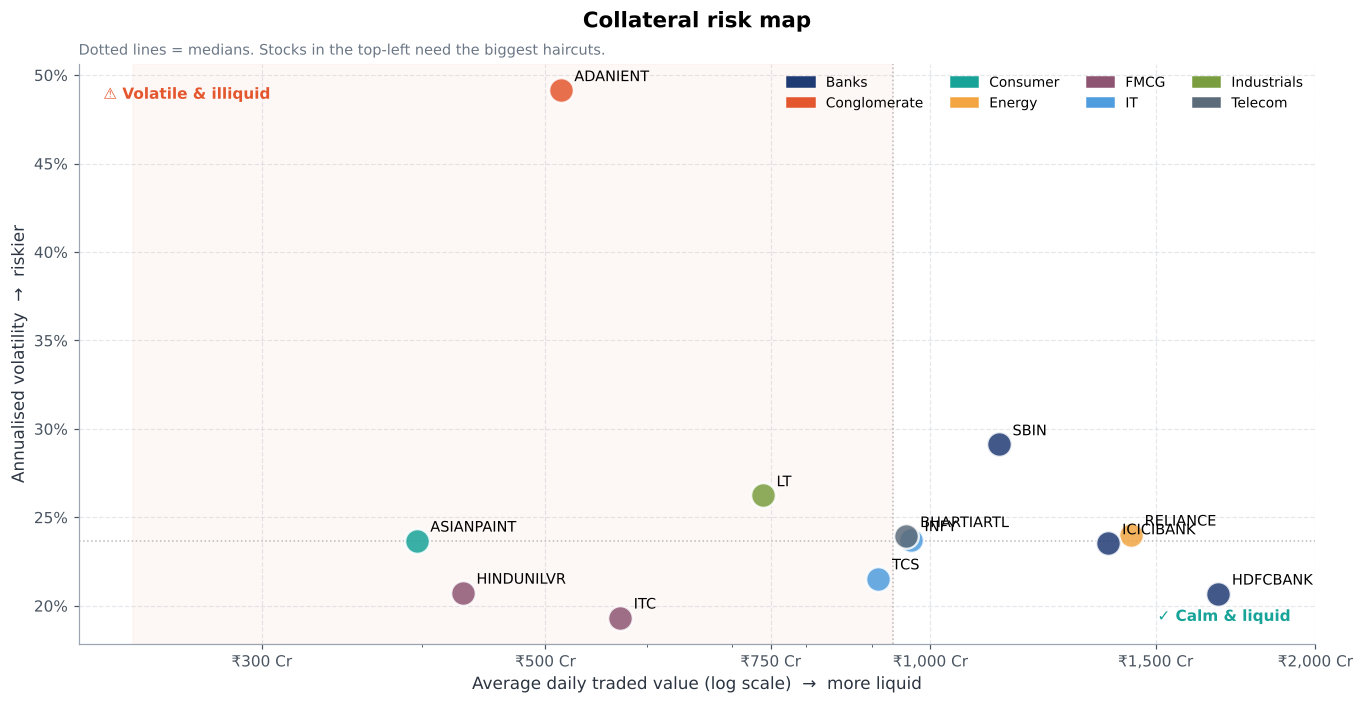

In [ ]:
fig, ax = plt.subplots(figsize=(12.5, 6.5))
x = adv / CRORE
y = sig_d * np.sqrt(252)
sector_list = sorted(set(SECTOR.values()))
sec_col = {s: CYCLE[i % len(CYCLE)] for i, s in enumerate(sector_list)}

ax.axvspan(x.min() * 0.6, x.median(), ymin=0, ymax=1, color=PALETTE["coral"], alpha=0.04)
ax.axhline(y.median(), color="#bbb", ls=":", lw=1)
ax.axvline(x.median(), color="#bbb", ls=":", lw=1)
for t in TICKERS:
    ax.scatter(x[t], y[t], s=260, color=sec_col[SECTOR[t]], alpha=0.85, edgecolor="white", linewidth=1.5, zorder=3)
    ax.annotate(SHORT[t], (x[t], y[t]), xytext=(9, 6), textcoords="offset points", fontsize=9.5)
ax.set_xscale("log")
ticks = [v for v in [50, 100, 200, 300, 500, 750, 1000, 1500, 2000, 3000, 5000] if x.min() * 0.6 <= v <= x.max() * 1.6]
ax.set_xticks(ticks)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"₹{v:,.0f} Cr"))
ax.xaxis.set_minor_formatter(mtick.NullFormatter())
ax.yaxis.set_major_formatter(pct_axis)
ax.set_xlabel("Average daily traded value (log scale)  →  more liquid")
ax.set_ylabel("Annualised volatility  →  riskier")
ax.text(0.02, 0.96, "⚠ Volatile & illiquid", transform=ax.transAxes, color=PALETTE["coral"], fontweight="bold", va="top")
ax.text(0.98, 0.04, "✓ Calm & liquid", transform=ax.transAxes, color=PALETTE["teal"], fontweight="bold", ha="right")
ax.legend(handles=[Patch(color=sec_col[s], label=s) for s in sector_list], ncol=4, loc="upper right", fontsize=9)
ax.set_title("Collateral risk map")
subtitle(ax, "Dotted lines = medians. Stocks in the top-left need the biggest haircuts.")
plt.tight_layout(); plt.show()

## 3. Market-risk haircut
The haircut must cover a **99% worst-case price fall over the MPOR**. Three ways to estimate it:

| Estimate | Formula | Behaviour |
|---|---|---|
| **Historical** | 1st percentile of all overlapping 10-day returns since 2019 | Includes the 2020 crash — conservative |
| **Current parametric** | $1 - e^{-z\,\sigma_{1y}\sqrt{10}}$ | Reacts to today's volatility |
| **Stressed** | Same, using the **worst** 1-year volatility | Very conservative, stable |

**Policy used here:** $H_{mkt} = \max(\text{historical}, \text{current parametric}, \text{floor})$ — never below what history shows, and it rises immediately if markets get choppier. The stressed figure is shown for reference.

In [ ]:
R10 = (prices / prices.shift(MPOR) - 1).dropna()           # overlapping 10-day returns

h_hist   = -R10.quantile(1 - CONFIDENCE)
h_param  = 1 - np.exp(-z * sig_d * np.sqrt(MPOR))
sig_str  = log_ret.rolling(250).std().max()
h_stress = 1 - np.exp(-z * sig_str * np.sqrt(MPOR))
h_mkt    = pd.concat([h_hist, h_param], axis=1).max(axis=1).clip(lower=HAIRCUT_FLOOR)

mkt_tbl = pd.DataFrame({"Historical": h_hist, "Current parametric": h_param,
                        "Stressed": h_stress, "→ Market haircut": h_mkt})
mkt_tbl.index = [SHORT[t] for t in mkt_tbl.index]
mkt_tbl.sort_values("→ Market haircut").style.format("{:.1%}").background_gradient(
    cmap="OrRd", subset=["→ Market haircut"])

,Historical,Current parametric,Stressed,→ Market haircut
HDFCBANK,10.6%,9.1%,16.0%,10.6%
TCS,10.6%,9.5%,15.6%,10.6%
ITC,11.4%,8.6%,14.8%,11.4%
HINDUNILVR,12.1%,9.2%,16.0%,12.1%
ASIANPAINT,12.2%,10.4%,15.2%,12.2%
BHARTIARTL,13.6%,10.5%,17.7%,13.6%
LT,14.0%,11.5%,19.1%,14.0%
ICICIBANK,14.2%,10.3%,17.8%,14.2%
RELIANCE,14.3%,10.5%,17.3%,14.3%
INFY,14.3%,10.4%,16.5%,14.3%


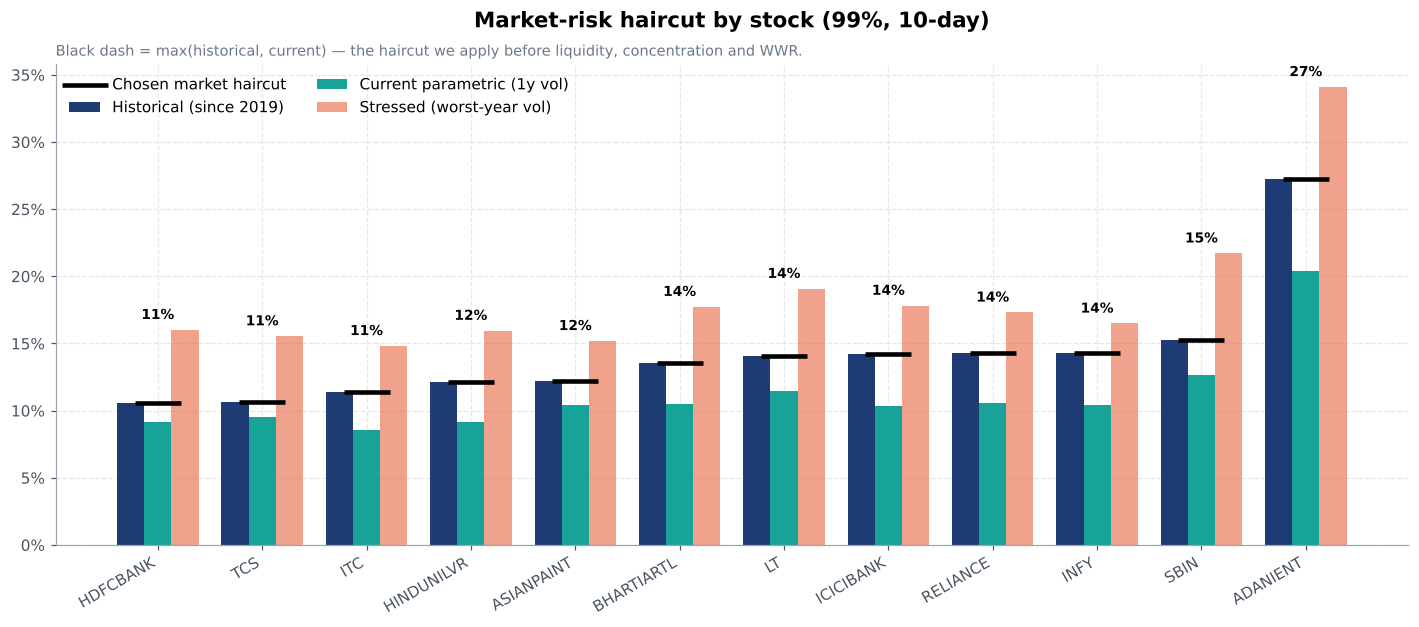

In [ ]:
order = h_mkt.sort_values().index
xx = np.arange(len(order)); w = 0.26
fig, ax = plt.subplots(figsize=(13, 5.8))
ax.bar(xx - w, h_hist[order],   w, color=PALETTE["navy"],  label="Historical (since 2019)")
ax.bar(xx,     h_param[order],  w, color=PALETTE["teal"],  label="Current parametric (1y vol)")
ax.bar(xx + w, h_stress[order], w, color=PALETTE["coral"], alpha=0.55, label="Stressed (worst-year vol)")
ax.scatter(xx, h_mkt[order], marker="_", s=900, color="black", linewidth=3, zorder=4, label="Chosen market haircut")
for i, t in enumerate(order):
    ax.text(i, max(h_hist[t], h_param[t], h_stress[t]) + 0.008, f"{h_mkt[t]:.0%}", ha="center", fontsize=9, fontweight="bold")
ax.set_xticks(xx, [SHORT[t] for t in order], rotation=30, ha="right")
ax.yaxis.set_major_formatter(pct_axis)
ax.set_title("Market-risk haircut by stock (99%, 10-day)")
subtitle(ax, "Black dash = max(historical, current) — the haircut we apply before liquidity, concentration and WWR.")
ax.legend(ncol=2, loc="upper left")
plt.tight_layout(); plt.show()

## 4. Liquidity add-on — when a position is too big to sell quickly

**Step 1: Days to liquidate.** The bank sells at most `PARTICIPATION` (10%) of daily volume:
$$D = \frac{\text{Position value}}{\text{participation} \times \text{ADV}}$$

**Step 2: Longer exposure.** Selling evenly over $D$ days keeps the bank exposed for longer, so the effective horizon grows:
$$h_{\text{eff}} = \text{MPOR} + \tfrac{1}{2}\max(D-1, 0), \qquad H_{mkt}^{\text{liq}} = H_{mkt}\sqrt{h_{\text{eff}}/\text{MPOR}}$$

**Step 3: Price impact.** Selling a large block pushes the price down. The empirical **square-root law**:
$$\text{Impact} = Y \cdot \sigma_{\text{daily}} \cdot \sqrt{\frac{Q}{\text{ADV}}}$$

$$H_{liq} = H_{mkt}\Big(\sqrt{h_{\text{eff}}/\text{MPOR}} - 1\Big) + \text{Impact}$$

In [ ]:
def liquidity_addon(ticker, position_value):
    """Returns (liquidity add-on, days to liquidate, effective horizon, impact)."""
    D = position_value / (PARTICIPATION * adv[ticker])
    h_eff = MPOR + 0.5 * max(D - 1, 0)
    horizon_part = h_mkt[ticker] * (np.sqrt(h_eff / MPOR) - 1)
    impact = IMPACT_Y * sig_d[ticker] * np.sqrt(position_value / adv[ticker])
    return horizon_part + impact, D, h_eff, impact

# Example: the same ₹300 Cr position in a liquid vs an illiquid stock
for t in ["HDFCBANK.NS", "ASIANPAINT.NS", "ADANIENT.NS"]:
    addon, D, h_eff, imp = liquidity_addon(t, 300 * CRORE)
    print(f"{SHORT[t]:<11} ₹300 Cr = {300*CRORE/adv[t]:4.2f}× ADV → {D:5.1f} days to sell, "
          f"horizon {h_eff:4.1f}d, impact {imp:5.1%}, liquidity add-on {addon:5.1%}")

HDFCBANK    ₹300 Cr = 0.18× ADV →   1.8 days to sell, horizon 10.4d, impact  0.6%, liquidity add-on  0.8%
ASIANPAINT  ₹300 Cr = 0.76× ADV →   7.6 days to sell, horizon 13.3d, impact  1.3%, liquidity add-on  3.2%
ADANIENT    ₹300 Cr = 0.58× ADV →   5.8 days to sell, horizon 12.4d, impact  2.4%, liquidity add-on  5.5%


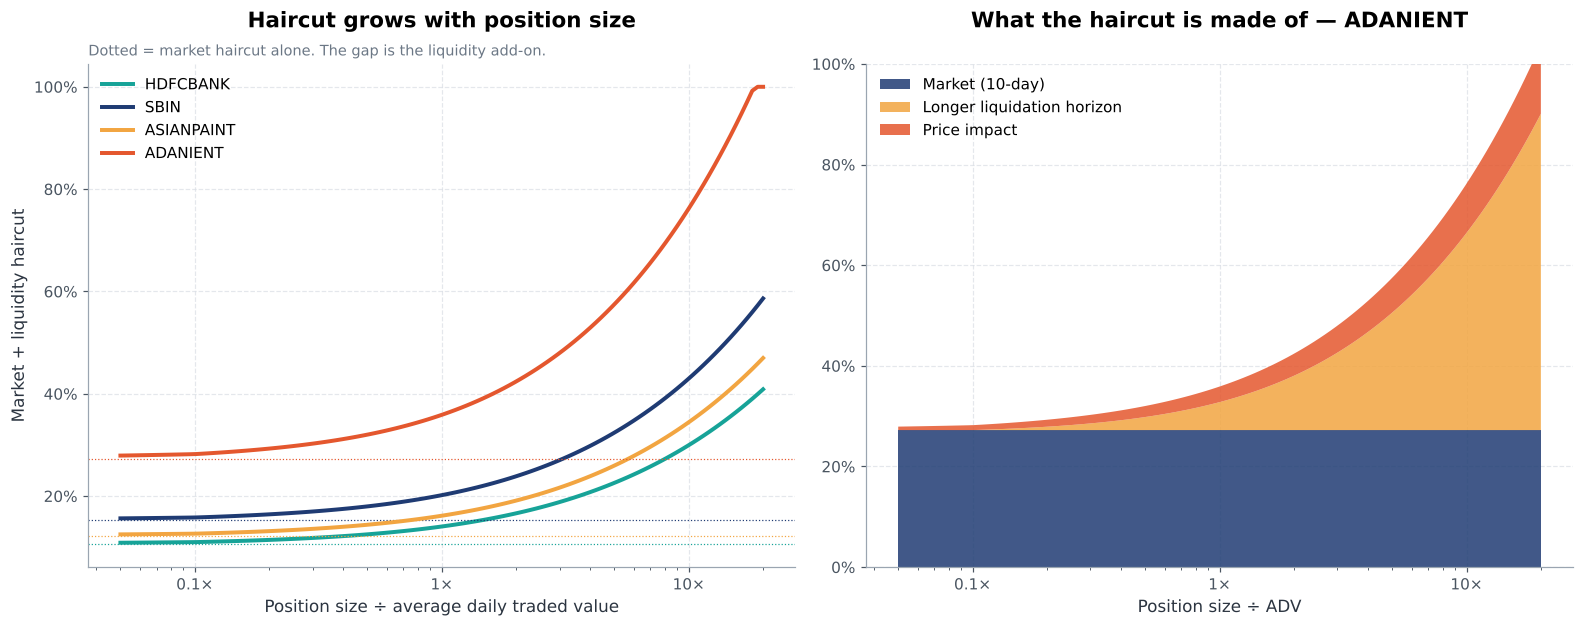

In [ ]:
mult = np.logspace(np.log10(0.05), np.log10(20), 120)          # position size as multiple of ADV
show = ["HDFCBANK.NS", "SBIN.NS", "ASIANPAINT.NS", "ADANIENT.NS"]

fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.8))
for t, col in zip(show, [PALETTE["teal"], PALETTE["navy"], PALETTE["gold"], PALETTE["coral"]]):
    tot = [min(1, h_mkt[t] + liquidity_addon(t, m * adv[t])[0]) for m in mult]
    axes[0].plot(mult, tot, lw=2.6, color=col, label=SHORT[t])
    axes[0].axhline(h_mkt[t], color=col, lw=0.8, ls=":")
axes[0].set_xscale("log")
axes[0].xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:g}×"))
axes[0].yaxis.set_major_formatter(pct_axis)
axes[0].set_xlabel("Position size ÷ average daily traded value")
axes[0].set_ylabel("Market + liquidity haircut")
axes[0].set_title("Haircut grows with position size")
subtitle(axes[0], "Dotted = market haircut alone. The gap is the liquidity add-on.")
axes[0].legend()

# Right: decomposition for the riskiest name
t = "ADANIENT.NS"
parts = np.array([[h_mkt[t],
                   h_mkt[t] * (np.sqrt((MPOR + 0.5 * max(m / PARTICIPATION - 1, 0)) / MPOR) - 1),
                   IMPACT_Y * sig_d[t] * np.sqrt(m)] for m in mult])
axes[1].stackplot(mult, parts.T, colors=[PALETTE["navy"], PALETTE["gold"], PALETTE["coral"]], alpha=0.85,
                  labels=["Market (10-day)", "Longer liquidation horizon", "Price impact"])
axes[1].set_xscale("log")
axes[1].xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:g}×"))
axes[1].yaxis.set_major_formatter(pct_axis)
axes[1].set_ylim(0, min(1, parts.sum(1).max() * 1.05))
axes[1].set_xlabel("Position size ÷ ADV")
axes[1].set_title(f"What the haircut is made of — {SHORT[t]}")
axes[1].legend(loc="upper left")
plt.tight_layout(); plt.show()

## 5. Concentration add-on
A pool of ten stocks rarely falls 40% at once. A pool that is **80% one stock** can. If one name exceeds the threshold share of the pool:
$$H_{conc} = \text{slope} \times \max\big(0,\; w_i - \text{threshold}\big)$$
We also report the **Herfindahl index** $HHI=\sum w_i^2$ and the **effective number of stocks** $1/HHI$ — a quick diversification score.

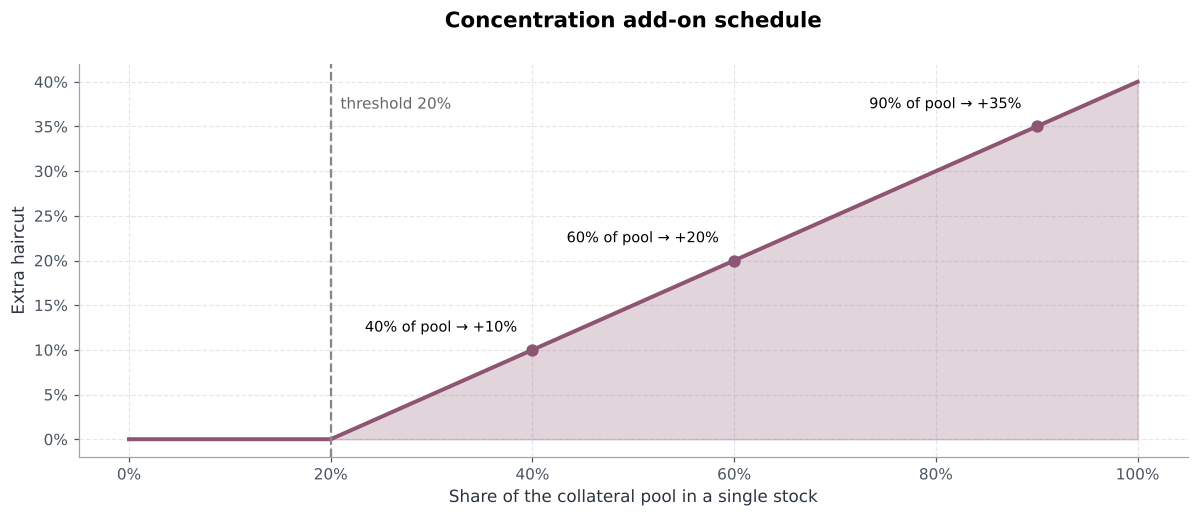

In [ ]:
def concentration_addon(weight):
    return CONC_SLOPE * max(0.0, weight - CONC_THRESHOLD)

wgrid = np.linspace(0, 1, 101)
fig, ax = plt.subplots(figsize=(11, 4.8))
ax.fill_between(wgrid, [concentration_addon(v) for v in wgrid], color=PALETTE["plum"], alpha=0.25)
ax.plot(wgrid, [concentration_addon(v) for v in wgrid], color=PALETTE["plum"], lw=2.6)
ax.axvline(CONC_THRESHOLD, color="#888", ls="--")
ax.text(CONC_THRESHOLD, 0.37, f"  threshold {CONC_THRESHOLD:.0%}", color="#666")
for wv in [0.4, 0.6, 0.9]:
    ax.scatter(wv, concentration_addon(wv), color=PALETTE["plum"], zorder=3, s=50)
    ax.annotate(f"{wv:.0%} of pool → +{concentration_addon(wv):.0%}", (wv, concentration_addon(wv)),
                xytext=(-10, 12), textcoords="offset points", ha="right", fontsize=9.5)
ax.xaxis.set_major_formatter(pct_axis); ax.yaxis.set_major_formatter(pct_axis)
ax.set_xlabel("Share of the collateral pool in a single stock")
ax.set_ylabel("Extra haircut")
ax.set_title("Concentration add-on schedule")
plt.tight_layout(); plt.show()

## 6. Wrong-way risk (WWR)
Collateral should protect the bank **when the client defaults**. If the collateral is likely to crash *at the same time*, it protects much less.

- **Specific WWR:** a client posting **its own shares or its group's shares** → collateral is **ineligible (100% haircut)**.
- **General WWR:** a client whose credit is tied to a sector (e.g. an **NBFC** depends on the banking system). Stocks highly correlated with that sector get a **multiplier**:
$$M_{WWR} = 1 + K \cdot \max(0, \rho - \rho^*)$$

Below we measure each stock's correlation with a **banking-sector proxy** (average of the bank stocks' returns), standing in for an NBFC client's credit quality.

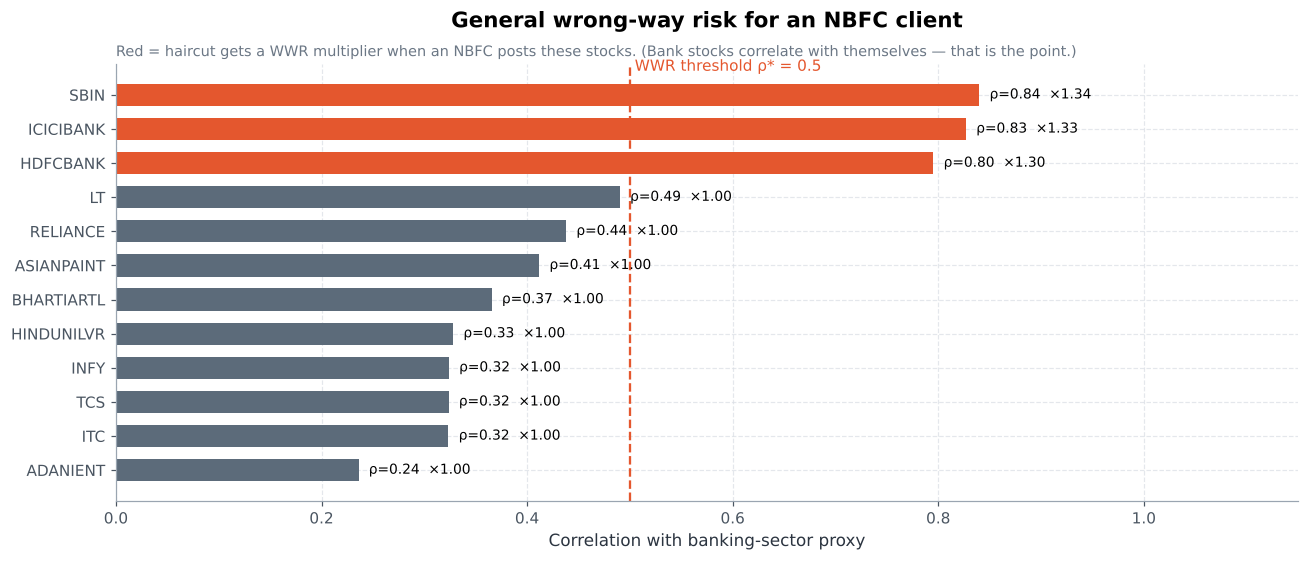

In [ ]:
banks = [t for t in TICKERS if SECTOR[t] == "Banks"]
client_proxy = log_ret[banks].mean(axis=1)                     # proxy for an NBFC client's fortunes
rho_bank = log_ret.apply(lambda s: s.corr(client_proxy))

def wwr_multiplier(ticker, rho=None):
    if rho is None:
        return 1.0
    return 1 + WWR_K * max(0.0, rho[ticker] - WWR_RHO)

srt = rho_bank.sort_values()
fig, ax = plt.subplots(figsize=(12, 5.2))
cols = [PALETTE["coral"] if v > WWR_RHO else PALETTE["slate"] for v in srt]
ax.barh([SHORT[t] for t in srt.index], srt, color=cols, height=0.65)
ax.axvline(WWR_RHO, color=PALETTE["coral"], ls="--", lw=1.5)
ax.text(WWR_RHO, len(srt) - 0.4, f" WWR threshold ρ* = {WWR_RHO}", color=PALETTE["coral"], va="bottom")
for i, (t, v) in enumerate(srt.items()):
    ax.text(v + 0.01, i, f"ρ={v:.2f}  ×{wwr_multiplier(t, rho_bank):.2f}", va="center", fontsize=9)
ax.set_xlim(0, 1.15)
ax.set_xlabel("Correlation with banking-sector proxy")
ax.set_title("General wrong-way risk for an NBFC client")
subtitle(ax, "Red = haircut gets a WWR multiplier when an NBFC posts these stocks. (Bank stocks correlate with themselves — that is the point.)")
plt.tight_layout(); plt.show()

## 7. The full haircut engine
Everything combined, position by position:
$$H_i = \min\Big(1,\; \big(H_{mkt,i} + H_{liq,i} + H_{conc,i}\big)\times M_{WWR,i}\Big), \qquad \text{ineligible} \Rightarrow H_i = 100\%$$

We run it on three realistic client pools:

| Client | Profile | What should happen |
|---|---|---|
| **A — Long-only fund** | ₹150 Cr in five liquid large-caps | Low haircut, mostly market risk |
| **B — "Archegos-style" fund** | ₹1,000 Cr, 60% in one volatile stock, positions > 1× ADV | Liquidity + concentration explode the haircut |
| **C — NBFC** | ₹150 Cr in bank shares, plus shares of its own group | WWR multiplier + one ineligible line |

In [ ]:
def haircut_engine(pool_cr, rho=None, ineligible=()):
    """pool_cr: {ticker: ₹ crore}. rho: correlation series for WWR (None = no WWR). ineligible: own/group shares."""
    pool = pd.Series(pool_cr, dtype=float) * CRORE
    weights = pool / pool.sum()
    rows = []
    for t, mv_t in pool.items():
        base = h_mkt[t]
        liq, D, h_eff, imp = liquidity_addon(t, mv_t)
        conc = concentration_addon(weights[t])
        pre_wwr = min(1.0, base + liq + conc)
        total = min(1.0, (base + liq + conc) * wwr_multiplier(t, rho))
        wwr = total - pre_wwr
        if t in ineligible:
            wwr, total = 1.0 - pre_wwr, 1.0
        rows.append({"Stock": SHORT[t], "Market value": mv_t, "Weight": weights[t], "×ADV": mv_t / adv[t],
                     "Days to sell": D, "Market": base, "Liquidity": min(liq, 1 - base),
                     "Concentration": min(conc, max(0, 1 - base - liq)), "WWR": max(wwr, 0), "Haircut": total})
    out = pd.DataFrame(rows).set_index("Stock")
    out["Lending value"] = out["Market value"] * (1 - out["Haircut"])
    return out

def pool_summary(df):
    mv_, lv = df["Market value"].sum(), df["Lending value"].sum()
    hhi = (df["Weight"] ** 2).sum()
    return pd.Series({"Market value": mv_, "Lending value": lv, "Effective haircut": 1 - lv / mv_,
                      "HHI": hhi, "Effective no. of stocks": 1 / hhi})

CLIENTS = {
    "A — Long-only fund":    dict(pool_cr={"RELIANCE.NS": 40, "HDFCBANK.NS": 30, "TCS.NS": 30, "INFY.NS": 25, "ITC.NS": 25}),
    "B — Archegos-style":    dict(pool_cr={"ADANIENT.NS": 600, "ASIANPAINT.NS": 300, "SBIN.NS": 100}),
    "C — NBFC":              dict(pool_cr={"HDFCBANK.NS": 50, "ICICIBANK.NS": 40, "SBIN.NS": 30, "LT.NS": 30},
                                  rho=rho_bank, ineligible=("LT.NS",)),   # pretend LT is the client's own group
}
results = {name: haircut_engine(**cfg) for name, cfg in CLIENTS.items()}
summary = pd.DataFrame({name: pool_summary(df) for name, df in results.items()}).T
summary.style.format({"Market value": lambda v: fmt_inr(v), "Lending value": lambda v: fmt_inr(v),
                      "Effective haircut": "{:.1%}", "HHI": "{:.2f}", "Effective no. of stocks": "{:.1f}"}
).background_gradient(subset=["Effective haircut"], cmap="RdYlGn_r")

,Market value,Lending value,Effective haircut,HHI,Effective no. of stocks
A — Long-only fund,₹150.0 Cr,₹129.8 Cr,13.5%,0.21,4.8
B — Archegos-style,"₹1,000.0 Cr",₹580.8 Cr,41.9%,0.46,2.2
C — NBFC,₹150.0 Cr,₹93.0 Cr,38.0%,0.26,3.8


In [ ]:
fmt = {"Market value": lambda v: fmt_inr(v), "Lending value": lambda v: fmt_inr(v), "Weight": "{:.0%}",
       "×ADV": "{:.2f}", "Days to sell": "{:.1f}", "Market": "{:.1%}", "Liquidity": "{:.1%}",
       "Concentration": "{:.1%}", "WWR": "{:.1%}", "Haircut": "{:.1%}"}
for name, df in results.items():
    display(df.style.format(fmt).set_caption(f"<b>{name}</b>").background_gradient(subset=["Haircut"], cmap="OrRd", vmin=0, vmax=1))

,Market value,Weight,×ADV,Days to sell,Market,Liquidity,Concentration,WWR,Haircut,Lending value
Stock,,,,,,,,,,
RELIANCE,₹40.0 Cr,27%,0.03,0.3,14.3%,0.3%,3.3%,0.0%,17.9%,₹32.8 Cr
HDFCBANK,₹30.0 Cr,20%,0.02,0.2,10.6%,0.2%,0.0%,0.0%,10.8%,₹26.8 Cr
TCS,₹30.0 Cr,20%,0.03,0.3,10.6%,0.2%,0.0%,0.0%,10.9%,₹26.7 Cr
INFY,₹25.0 Cr,17%,0.03,0.3,14.3%,0.2%,0.0%,0.0%,14.6%,₹21.4 Cr
ITC,₹25.0 Cr,17%,0.04,0.4,11.4%,0.3%,0.0%,0.0%,11.7%,₹22.1 Cr


,Market value,Weight,×ADV,Days to sell,Market,Liquidity,Concentration,WWR,Haircut,Lending value
Stock,,,,,,,,,,
ADANIENT,₹600.0 Cr,60%,1.17,11.7,27.2%,9.8%,20.0%,0.0%,57.1%,₹257.6 Cr
ASIANPAINT,₹300.0 Cr,30%,0.76,7.6,12.2%,3.2%,5.0%,0.0%,20.3%,₹239.0 Cr
SBIN,₹100.0 Cr,10%,0.09,0.9,15.2%,0.5%,0.0%,0.0%,15.8%,₹84.2 Cr


,Market value,Weight,×ADV,Days to sell,Market,Liquidity,Concentration,WWR,Haircut,Lending value
Stock,,,,,,,,,,
HDFCBANK,₹50.0 Cr,33%,0.03,0.3,10.6%,0.2%,6.7%,5.2%,22.6%,₹38.7 Cr
ICICIBANK,₹40.0 Cr,27%,0.03,0.3,14.2%,0.3%,3.3%,5.8%,23.6%,₹30.6 Cr
SBIN,₹30.0 Cr,20%,0.03,0.3,15.2%,0.3%,0.0%,5.3%,20.8%,₹23.8 Cr
LT,₹30.0 Cr,20%,0.04,0.4,14.0%,0.3%,0.0%,85.6%,100.0%,₹0


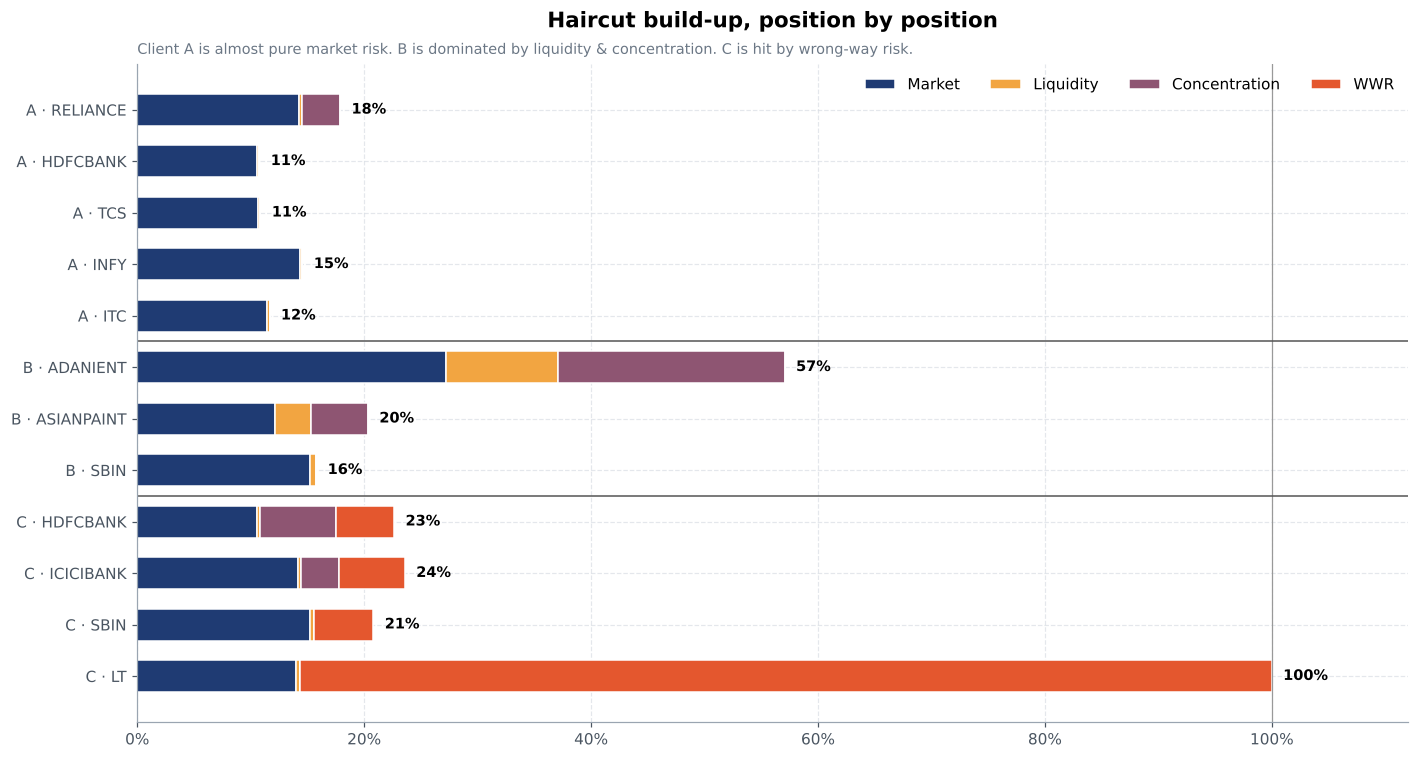

In [ ]:
# Stacked haircut components for every position of every client
comp_cols = ["Market", "Liquidity", "Concentration", "WWR"]
comp_colors = [PALETTE["navy"], PALETTE["gold"], PALETTE["plum"], PALETTE["coral"]]

labels, data = [], []
for name, df in results.items():
    for stock, r in df.iterrows():
        labels.append(f"{name.split(' — ')[0]} · {stock}")
        data.append(r[comp_cols].values)
data = np.array(data, dtype=float)

fig, ax = plt.subplots(figsize=(13, 7))
left = np.zeros(len(data))
for j, (c, col) in enumerate(zip(comp_cols, comp_colors)):
    ax.barh(labels, data[:, j], left=left, color=col, label=c, height=0.62, edgecolor="white")
    left += data[:, j]
for i, tot in enumerate(left):
    ax.text(tot + 0.01, i, f"{tot:.0%}", va="center", fontsize=9.5, fontweight="bold")
ax.invert_yaxis()
ax.set_xlim(0, 1.12)
ax.xaxis.set_major_formatter(pct_axis)
ax.axvline(1, color="#999", lw=0.8)
# separators between clients
cuts = np.cumsum([len(df) for df in results.values()])[:-1]
for cpos in cuts:
    ax.axhline(cpos - 0.5, color="#555", lw=1)
ax.set_title("Haircut build-up, position by position")
subtitle(ax, "Client A is almost pure market risk. B is dominated by liquidity & concentration. C is hit by wrong-way risk.")
ax.legend(ncol=4, loc="upper right")
plt.tight_layout(); plt.show()

### Waterfall — from market value to lending value (Client B)
This is the chart you would put in front of a credit committee: *"the client says the collateral is worth ₹1,000 Cr; here is why we will lend far less."*

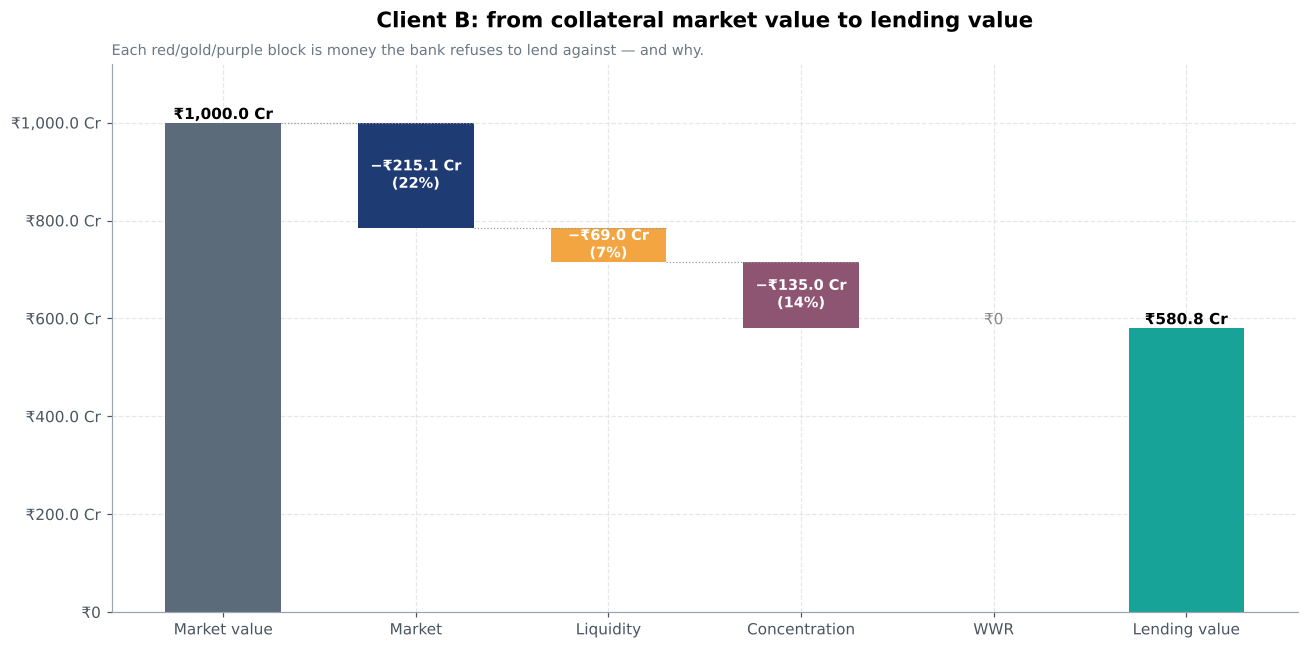

In [ ]:
df = results["B — Archegos-style"]
mv_B = df["Market value"].sum()
steps = [("Market value", mv_B)] + [(c, -(df[c] * df["Market value"]).sum()) for c in comp_cols]
steps.append(("Lending value", df["Lending value"].sum()))

fig, ax = plt.subplots(figsize=(12, 6))
running = 0
for i, (lab, val) in enumerate(steps):
    if lab in ("Market value", "Lending value"):
        ax.bar(i, val, color=PALETTE["teal"] if lab == "Lending value" else PALETTE["slate"], width=0.6)
        ax.text(i, val, fmt_inr(val), ha="center", va="bottom", fontweight="bold")
        running = val
    else:
        if abs(val) < 1:
            ax.text(i, running, "₹0", ha="center", va="bottom", color="#888")
            continue
        ax.bar(i, val, bottom=running, color=comp_colors[comp_cols.index(lab)], width=0.6)
        ax.text(i, running + val / 2, f"{fmt_inr(val)}\n({-val / mv_B:.0%})", ha="center", va="center",
                color="white", fontweight="bold", fontsize=9.5)
        ax.plot([i - 0.7, i + 0.3], [running, running], color="#999", lw=0.8, ls=":")
        running += val
ax.set_xticks(range(len(steps)), [s[0] for s in steps])
ax.set_ylim(0, mv_B * 1.12)
ax.yaxis.set_major_formatter(inr_axis)
ax.set_title("Client B: from collateral market value to lending value")
subtitle(ax, "Each red/gold/purple block is money the bank refuses to lend against — and why.")
plt.tight_layout(); plt.show()

## 8. Stress test — does the collateral still cover the loan?
Assume each client has **borrowed the maximum** allowed (loan = lending value). Then shock the collateral and check for a **shortfall** (a loss to the bank).

We compare two policies:
- 🔸 **Flat 15% haircut** on every stock (a naive policy)
- 🔹 **Our model** haircuts

Scenarios:
1. **Worst historical 10-day move** for that exact pool (joint, so correlations are real)
2. **Single-name crash:** the largest holding falls 40%, everything else 10%
3. **Crash + forced sale:** scenario 2, and the bank also pays price impact at **double** normal volatility

In [ ]:
FLAT_HAIRCUT = 0.15

def stress_pool(df_pool, pool_cr):
    tick = [t for t in pool_cr]
    mv_pos = pd.Series({t: pool_cr[t] * CRORE for t in tick})
    port_r10 = (R10[tick] * mv_pos).sum(axis=1)
    worst_day = port_r10.idxmin()
    shocks = {
        "Worst historical 10-day": R10.loc[worst_day, tick],
        "Single-name crash": pd.Series({t: (-0.40 if t == mv_pos.idxmax() else -0.10) for t in tick}),
    }
    out = {}
    for sname, shock in shocks.items():
        out[sname] = (mv_pos * (1 + shock)).sum()
    impact = pd.Series({t: IMPACT_Y * 2 * sig_d[t] * np.sqrt(mv_pos[t] / adv[t]) for t in tick})
    crash = shocks["Single-name crash"]
    out["Crash + forced sale"] = (mv_pos * (1 + crash) * (1 - impact.clip(upper=0.9))).sum()
    return out, worst_day

rows = []
for name, cfg in CLIENTS.items():
    dfp = results[name]
    mv_total = dfp["Market value"].sum()
    loan_model = dfp["Lending value"].sum()
    loan_flat = mv_total * (1 - FLAT_HAIRCUT)
    stressed, wd = stress_pool(dfp, cfg["pool_cr"])
    for sname, val in stressed.items():
        rows.append({"Client": name.split(" — ")[0], "Scenario": sname,
                     "Loss (flat 15%)": max(0, loan_flat - val), "Loss (model)": max(0, loan_model - val),
                     "Collateral after shock": val})
stress = pd.DataFrame(rows)
stress.style.format({"Loss (flat 15%)": lambda v: fmt_inr(v), "Loss (model)": lambda v: fmt_inr(v),
                     "Collateral after shock": lambda v: fmt_inr(v)}).hide(axis="index")

Client,Scenario,Loss (flat 15%),Loss (model),Collateral after shock
A,Worst historical 10-day,₹0,₹82.8 L,₹129.0 Cr
A,Single-name crash,₹4.5 Cr,₹6.8 Cr,₹123.0 Cr
A,Crash + forced sale,₹5.1 Cr,₹7.4 Cr,₹122.4 Cr
B,Worst historical 10-day,₹126.3 Cr,₹0,₹723.7 Cr
B,Single-name crash,₹130.0 Cr,₹0,₹720.0 Cr
B,Crash + forced sale,₹162.1 Cr,₹0,₹687.9 Cr
C,Worst historical 10-day,₹7.6 Cr,₹0,₹119.9 Cr
C,Single-name crash,₹7.5 Cr,₹0,₹120.0 Cr
C,Crash + forced sale,₹8.2 Cr,₹0,₹119.3 Cr


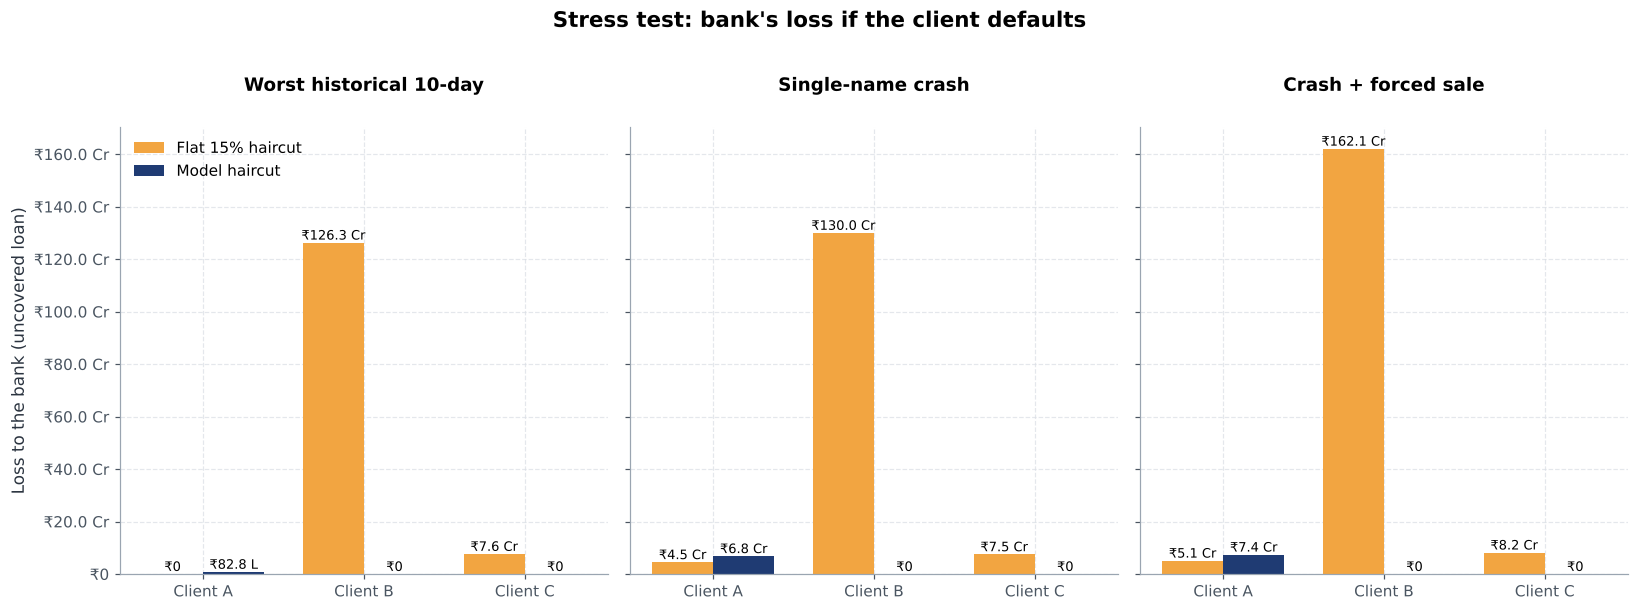

In [ ]:
scen_names = stress["Scenario"].unique()
fig, axes = plt.subplots(1, len(scen_names), figsize=(15, 5.4), sharey=True)
for ax, sname in zip(axes, scen_names):
    sub = stress[stress["Scenario"] == sname].set_index("Client")
    xx = np.arange(len(sub)); w = 0.38
    b1 = ax.bar(xx - w/2, sub["Loss (flat 15%)"], w, color=PALETTE["gold"], label="Flat 15% haircut")
    b2 = ax.bar(xx + w/2, sub["Loss (model)"],    w, color=PALETTE["navy"], label="Model haircut")
    for bars in (b1, b2):
        for b in bars:
            h = b.get_height()
            ax.text(b.get_x() + b.get_width() / 2, h, "₹0" if h < 1 else fmt_inr(h),
                    ha="center", va="bottom", fontsize=8.5, rotation=0)
    ax.set_xticks(xx, [f"Client {c}" for c in sub.index])
    ax.set_title(sname, fontsize=12)
    ax.yaxis.set_major_formatter(inr_axis)
axes[0].set_ylabel("Loss to the bank (uncovered loan)")
axes[0].legend(loc="upper left")
fig.suptitle("Stress test: bank's loss if the client defaults", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout(); plt.show()

**Read-out:**
- **Client B** — a flat 15% haircut leaves the bank badly exposed: exactly the Archegos failure mode. The model's liquidity and concentration add-ons absorb the loss.
- **Client C** — the WWR multiplier and the ineligible group shares protect the bank.
- **Client A** — the model lends *slightly more* than the flat policy (the pool is liquid and diversified), so an extreme single-name crash can leave a small shortfall. That is the honest trade-off of a **risk-sensitive** model: it rewards good collateral. The residual is handled by **daily margin calls** and **concentration limits** — a point worth making in an interview.

## 9. Out-of-sample backtest of the market haircut
A haircut is a **prediction**: "the price will not fall more than $H$ over 10 days, 99% of the time." We test it honestly:
1. Every 10 days, calibrate the haircut using **only the previous 2 years** of data (rolling, no peeking).
2. Compare it with the **actual** next 10-day return.
3. Count **breaches** (actual fall > haircut). The target is ≈1%.

We also show the **binomial 95% band** — the range of breach rates consistent with a correct 1% model given the number of tests.

In [ ]:
CAL_WINDOW = 500
test_idx = range(CAL_WINDOW + MPOR, len(prices) - MPOR, MPOR)      # non-overlapping test windows
breach = {t: [] for t in TICKERS}
for i in test_idx:
    hist = prices.iloc[i - CAL_WINDOW:i]
    r10_hist = (hist / hist.shift(MPOR) - 1).dropna()
    lr = np.log(hist).diff().dropna()
    h_hist_t  = -r10_hist.quantile(1 - CONFIDENCE)
    h_param_t = 1 - np.exp(-z * lr.iloc[-250:].std() * np.sqrt(MPOR))
    h_t = pd.concat([h_hist_t, h_param_t], axis=1).max(axis=1).clip(lower=HAIRCUT_FLOOR)
    fwd = prices.iloc[i + MPOR] / prices.iloc[i] - 1
    for t in TICKERS:
        breach[t].append(fwd[t] < -h_t[t])

n_tests = len(list(test_idx))
rate = pd.Series({t: np.mean(v) for t, v in breach.items()}).sort_values()
lo, hi = stats.binom.ppf([0.025, 0.975], n_tests, 1 - CONFIDENCE) / n_tests
print(f"Tests per stock: {n_tests}   |   95% band for a correct 1% model: {lo:.1%} – {hi:.1%}")
print(f"Average breach rate across stocks: {rate.mean():.2%}")

Tests per stock: 151   |   95% band for a correct 1% model: 0.0% – 2.6%
Average breach rate across stocks: 0.83%


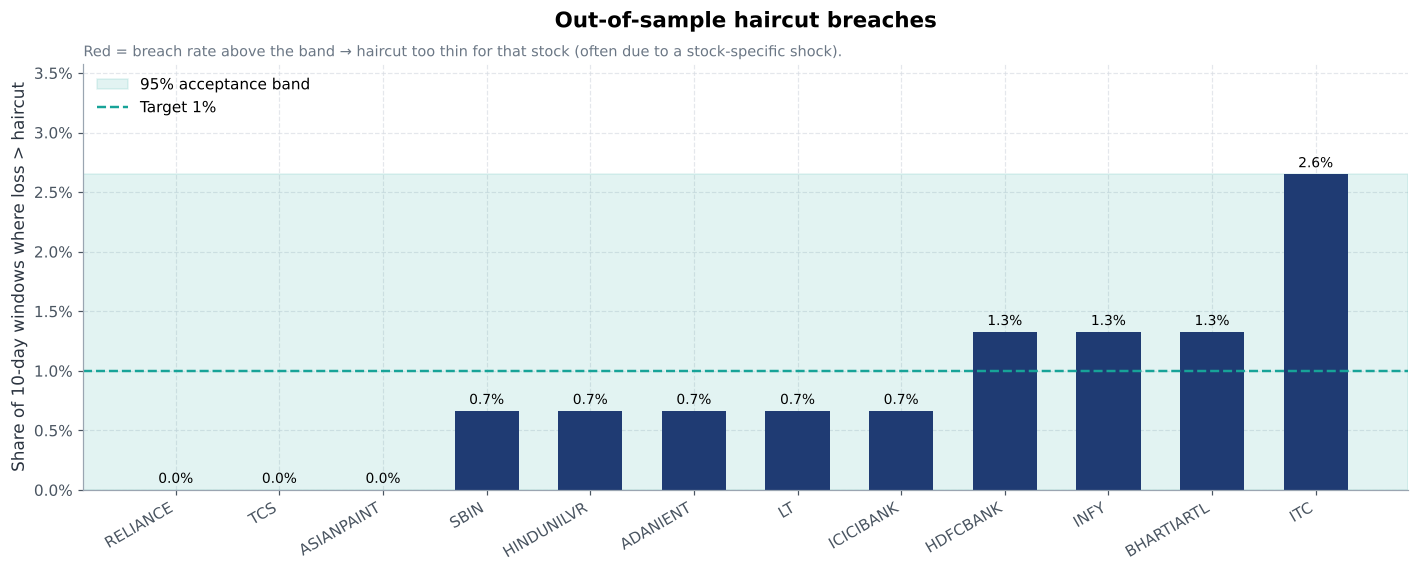

In [ ]:
fig, ax = plt.subplots(figsize=(13, 5.3))
ax.axhspan(lo, hi, color=PALETTE["teal"], alpha=0.12, label="95% acceptance band")
ax.axhline(1 - CONFIDENCE, color=PALETTE["teal"], ls="--", lw=1.6, label="Target 1%")
cols = [PALETTE["coral"] if r > hi else PALETTE["navy"] for r in rate]
ax.bar([SHORT[t] for t in rate.index], rate, color=cols, width=0.62)
for i, r in enumerate(rate):
    ax.text(i, r + 0.0006, f"{r:.1%}", ha="center", fontsize=9)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=1))
ax.set_ylim(0, max(rate.max(), hi) * 1.35)
ax.set_xticklabels([SHORT[t] for t in rate.index], rotation=30, ha="right")
ax.set_ylabel("Share of 10-day windows where loss > haircut")
ax.set_title("Out-of-sample haircut breaches")
subtitle(ax, "Red = breach rate above the band → haircut too thin for that stock (often due to a stock-specific shock).")
ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

## 10. The published haircut grid
Banks publish **haircut schedules** so sales teams know in advance what a client will be able to borrow. Below: total haircut (market + liquidity) for each stock at different position sizes, assuming the position is not concentrated.

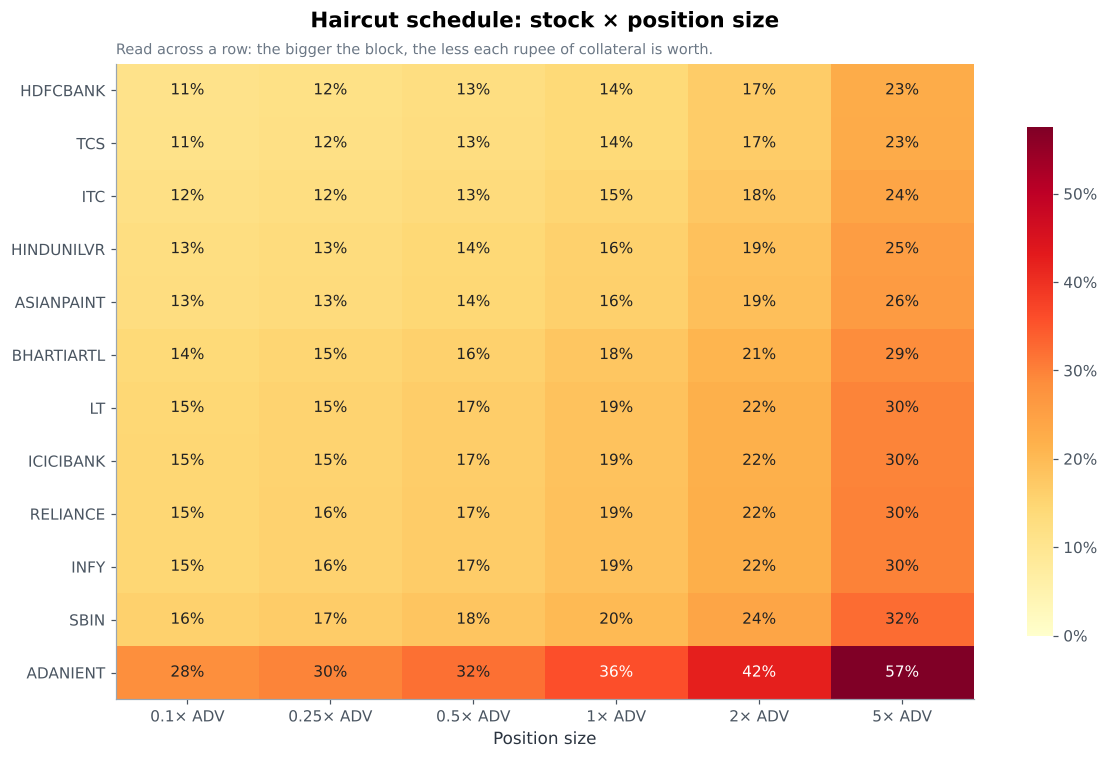

In [ ]:
sizes = [0.1, 0.25, 0.5, 1, 2, 5]                      # position size as multiple of ADV
grid = pd.DataFrame({f"{s:g}× ADV": [min(1, h_mkt[t] + liquidity_addon(t, s * adv[t])[0]) for t in TICKERS]
                     for s in sizes}, index=[SHORT[t] for t in TICKERS])
grid = grid.loc[grid.iloc[:, 0].sort_values().index]

fig, ax = plt.subplots(figsize=(11, 7))
im = ax.imshow(grid.values, cmap="YlOrRd", aspect="auto", vmin=0, vmax=min(1, grid.values.max()))
for i in range(grid.shape[0]):
    for j in range(grid.shape[1]):
        v = grid.values[i, j]
        ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=10,
                color="white" if v > grid.values.max() * 0.6 else "#222")
ax.set_xticks(range(len(sizes)), grid.columns)
ax.set_yticks(range(len(grid)), grid.index)
ax.grid(False)
cb = fig.colorbar(im, ax=ax, shrink=0.8, format=mtick.PercentFormatter(1.0, decimals=0)); cb.outline.set_visible(False)
ax.set_xlabel("Position size")
ax.set_title("Haircut schedule: stock × position size")
subtitle(ax, "Read across a row: the bigger the block, the less each rupee of collateral is worth.")
plt.tight_layout(); plt.show()

## 11. Summary

In [ ]:
print(f"Data source: {DATA_SOURCE}\n")
key = summary.copy()
key["Market value"] = key["Market value"].map(fmt_inr)
key["Lending value"] = key["Lending value"].map(fmt_inr)
key["Effective haircut"] = key["Effective haircut"].map("{:.1%}".format)
key["Worst stress loss (flat 15%)"] = [fmt_inr(stress[stress.Client == n.split(" — ")[0]]["Loss (flat 15%)"].max()) for n in summary.index]
key["Worst stress loss (model)"]    = [fmt_inr(stress[stress.Client == n.split(" — ")[0]]["Loss (model)"].max()) for n in summary.index]
key[["Market value", "Lending value", "Effective haircut", "Worst stress loss (flat 15%)", "Worst stress loss (model)"]]

Data source: Simulated (offline fallback)



,Market value,Lending value,Effective haircut,Worst stress loss (flat 15%),Worst stress loss (model)
A — Long-only fund,₹150.0 Cr,₹129.8 Cr,13.5%,₹5.1 Cr,₹7.4 Cr
B — Archegos-style,"₹1,000.0 Cr",₹580.8 Cr,41.9%,₹162.1 Cr,₹0
C — NBFC,₹150.0 Cr,₹93.0 Cr,38.0%,₹8.2 Cr,₹0
